# Il modello Beta–Bernoulli: massima verosimiglianza, MAP e approccio pienamente bayesiano

Questo notebook illustra, sul modello più semplice possibile, i tre approcci all'apprendimento di un modello probabilistico discussi nelle note: la **massima verosimiglianza** (ML), la stima **maximum a posteriori** (MAP) e l'approccio **pienamente bayesiano**. Sono gli stessi tre approcci visti per la regressione lineare; qui tutti i calcoli si riducono a contare, e le differenze tra gli approcci sono particolarmente trasparenti.

## Il modello

Osserviamo $n$ valori binari $x_1,\ldots,x_n\in\{0,1\}$, ad esempio i risultati di lanci ripetuti di una moneta con probabilità di testa $\phi$ sconosciuta. Il modello di **Bernoulli** assume che le osservazioni siano indipendenti e identicamente distribuite, con
$$p(x\mid\phi)=\phi^x(1-\phi)^{1-x},\qquad P(x=1)=\phi.$$
È un modello parametrico con un solo parametro, $\phi\in[0,1]$. Come per la regressione, il problema è stimare $\phi$ dai dati e, soprattutto, **predire** le osservazioni future.

## I tre approcci, in sintesi

| | Massima verosimiglianza | MAP | Pienamente bayesiano |
|---|---|---|---|
| $\phi$ è | una costante sconosciuta | una variabile casuale con prior $\mathrm{Beta}(\alpha,\beta)$ | una variabile casuale con prior $\mathrm{Beta}(\alpha,\beta)$ |
| Cosa si calcola | $\phi_{ML}=\dfrac{n_1}{n}$ | $\phi_{MAP}=\dfrac{n_1+\alpha-1}{n+\alpha+\beta-2}$, moda del posterior | il posterior $\mathrm{Beta}(\alpha+n_1,\beta+n_0)$ |
| Predizione di $x=1$ | $\phi_{ML}$ | $\phi_{MAP}$ | $\mathbb{E}[\phi\mid\mathbf{x}]=\dfrac{\alpha+n_1}{\alpha+\beta+n}$ |
| Incertezza su $\phi$ | nessuna | nessuna | intervalli di credibilità, predittive più ampie |

dove $n_1$ è il numero di successi (uni) e $n_0=n-n_1$ il numero di insuccessi.

## Preparazione

Oltre a `numpy`, usiamo `scipy.stats` per le distribuzioni Beta e binomiale, `scipy.special` per la funzione Beta, e `seaborn` (con `pandas` per organizzare i dati da disegnare) per i grafici. Seaborn lavora naturalmente con dati in formato "lungo", una riga per punto con colonne che identificano le serie: per questo i grafici con più curve costruiscono prima un `DataFrame` e lo passano a `sns.lineplot` con l'argomento `hue`. Fissiamo il seme del generatore di numeri casuali, in modo che i risultati commentati siano riproducibili; cambiandolo, o eliminando la riga, si ottengono sequenze diverse.

In [1]:
%matplotlib inline
import numpy as np
import scipy.stats as st
from scipy.special import betaln
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

In [2]:
# stile seaborn: sfondo con griglia, palette coerente per tutti i grafici
sns.set_theme(style='whitegrid', context='notebook', palette='deep')
plt.rcParams['figure.figsize'] = (12, 6)

# un colore fisso per ciascun approccio, usato in tutti i grafici
pal = sns.color_palette('deep')
c_ml, c_map, c_bayes, c_post = pal[3], pal[2], pal[4], pal[0]

## I dati

Simuliamo una moneta sbilanciata con probabilità di testa $\phi=0.3$, sconosciuta al learner, e generiamo una sequenza di $200$ lanci. Nel seguito useremo prefissi di lunghezza crescente di questa sequenza, per osservare come cambiano le stime all'aumentare dei dati.

In [3]:
phi_true = 0.3
n_max = 200
x = st.bernoulli.rvs(phi_true, size=n_max)

def counts(x):
    # numero di successi e di insuccessi
    n1 = int(x.sum())
    return n1, len(x) - n1

print('primi 20 lanci:', x[:20])
print('successi nei 200 lanci: {0}'.format(counts(x)[0]))

primi 20 lanci: [0 1 1 0 0 0 0 1 0 1 0 1 1 0 0 0 0 0 0 0]
successi nei 200 lanci: 60


## Massima verosimiglianza

La **verosimiglianza** è la probabilità della sequenza osservata, vista come funzione del parametro. Per osservazioni indipendenti,
$$L(\phi\mid\mathbf{x})=\prod_{i=1}^n\phi^{x_i}(1-\phi)^{1-x_i}=\phi^{n_1}(1-\phi)^{n_0}:$$
ogni successo contribuisce un fattore $\phi$, ogni insuccesso un fattore $1-\phi$. La verosimiglianza dipende dai dati solo attraverso i conteggi $n_1$ e $n_0$, che sono quindi **statistiche sufficienti**: l'ordine dei lanci non conta. La log-verosimiglianza è $l(\phi\mid\mathbf{x})=n_1\ln\phi+n_0\ln(1-\phi)$, e annullandone la derivata
$$\frac{n_1}{\phi}-\frac{n_0}{1-\phi}=0\quad\Longrightarrow\quad\phi_{ML}=\frac{n_1}{n}:$$
la stima di massima verosimiglianza è la **frequenza osservata** dei successi.

La predizione, per un nuovo lancio, usa il valore stimato come se fosse esatto: $p(x=1\mid\mathbf{x})\approx\phi_{ML}$.

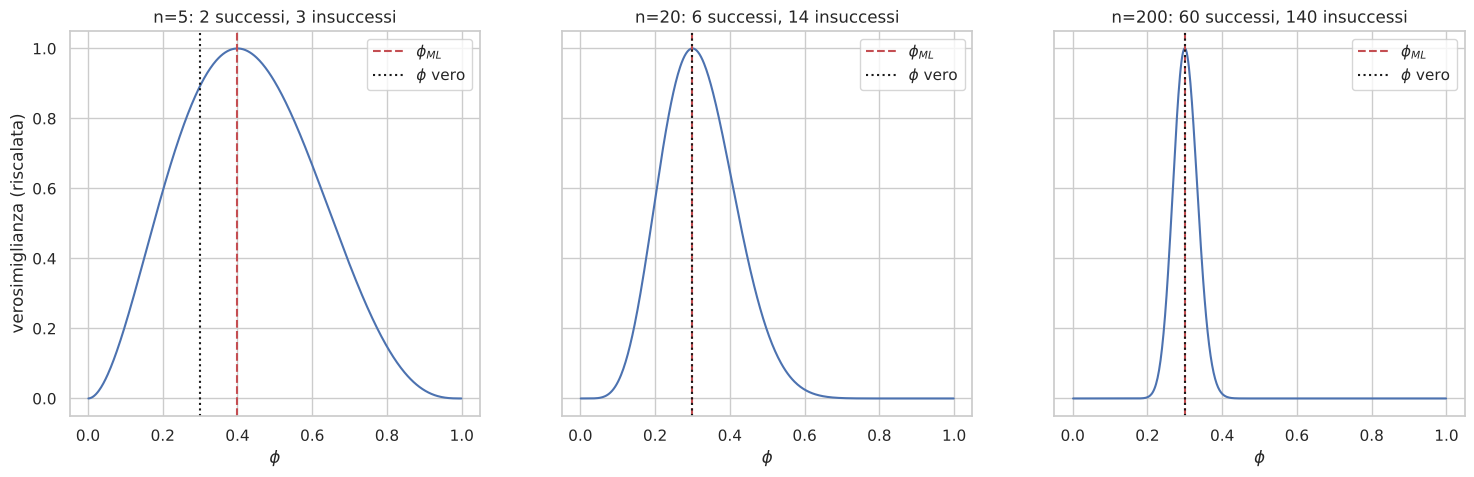

In [4]:
def phi_ml(x):
    n1, n0 = counts(x)
    return n1/(n1+n0)

def log_likelihood(phi, n1, n0):
    return n1*np.log(phi) + n0*np.log(1-phi)

phis = np.linspace(0.001, 0.999, 500)
fig, axs = plt.subplots(1, 3, figsize=(18,5), sharey=True)
for ax, n in zip(axs, [5, 20, 200]):
    n1, n0 = counts(x[:n])
    ll = log_likelihood(phis, n1, n0)
    sns.lineplot(x=phis, y=np.exp(ll - ll.max()), color=c_post, ax=ax)
    ax.axvline(phi_ml(x[:n]), color=c_ml, ls='--', lw=1.5, label=r'$\phi_{ML}$')
    ax.axvline(phi_true, color='k', ls=':', lw=1.5, label=r'$\phi$ vero')
    ax.set(title='n={0}: {1} successi, {2} insuccessi'.format(n, n1, n0), xlabel=r'$\phi$')
    ax.legend()
axs[0].set_ylabel('verosimiglianza (riscalata)')
plt.show()

I grafici mostrano la verosimiglianza, riscalata in modo che il massimo valga $1$, per $5$, $20$ e $200$ osservazioni. Il massimo è sempre nella frequenza osservata. Al crescere di $n$ la verosimiglianza diventa sempre più **concentrata**: i dati escludono valori di $\phi$ sempre più vicini a quello stimato. Con pochi dati, però, la funzione è molto larga, e il suo massimo è soltanto uno tra molti valori quasi altrettanto plausibili: la massima verosimiglianza sceglie quel punto e ignora tutti gli altri.

### Il problema del "cigno nero"

Il caso estremo è quello di pochissime osservazioni. Dopo un solo lancio, la stima è $\phi_{ML}=0$ o $\phi_{ML}=1$: un modello che, dopo aver visto una sola testa, assegna probabilità **zero** a tutte le croci future. È la forma più estrema di **overfitting**: il modello riproduce esattamente il campione osservato, e non lascia spazio a esiti non ancora visti. Il problema non riguarda solo $n=1$: con $\phi=0.3$, la probabilità di non osservare alcun successo in $n$ lanci è $0.7^n$, ancora circa $3\%$ con $n=10$.

In [5]:
for n in [1, 2, 3, 5, 10]:
    print('n={0:2d}: probabilita\' di zero successi = {1:.3f}, in tal caso phi_ML = 0'.format(n, 0.7**n))

n= 1: probabilita' di zero successi = 0.700, in tal caso phi_ML = 0
n= 2: probabilita' di zero successi = 0.490, in tal caso phi_ML = 0
n= 3: probabilita' di zero successi = 0.343, in tal caso phi_ML = 0
n= 5: probabilita' di zero successi = 0.168, in tal caso phi_ML = 0
n=10: probabilita' di zero successi = 0.028, in tal caso phi_ML = 0


## Il prior Beta

L'approccio bayesiano tratta $\phi$ come una variabile casuale, con una distribuzione **a priori** che esprime ciò che si crede prima di osservare i dati. Per una probabilità, la scelta naturale è la distribuzione **Beta**, definita su $[0,1]$:
$$p(\phi\mid\alpha,\beta)=\mathrm{Beta}(\phi\mid\alpha,\beta)=\frac{\Gamma(\alpha+\beta)}{\Gamma(\alpha)\Gamma(\beta)}\,\phi^{\alpha-1}(1-\phi)^{\beta-1},$$
con media $\frac{\alpha}{\alpha+\beta}$ e, per $\alpha,\beta>1$, moda $\frac{\alpha-1}{\alpha+\beta-2}$. I due **iperparametri** hanno un'interpretazione semplice come **pseudo-conteggi**: il prior si comporta come se, prima di osservare i dati, si fossero già visti $\alpha-1$ successi e $\beta-1$ insuccessi. La somma $\alpha+\beta$ misura quindi la **forza** del prior, cioè quanti dati reali servono per contraddirlo.

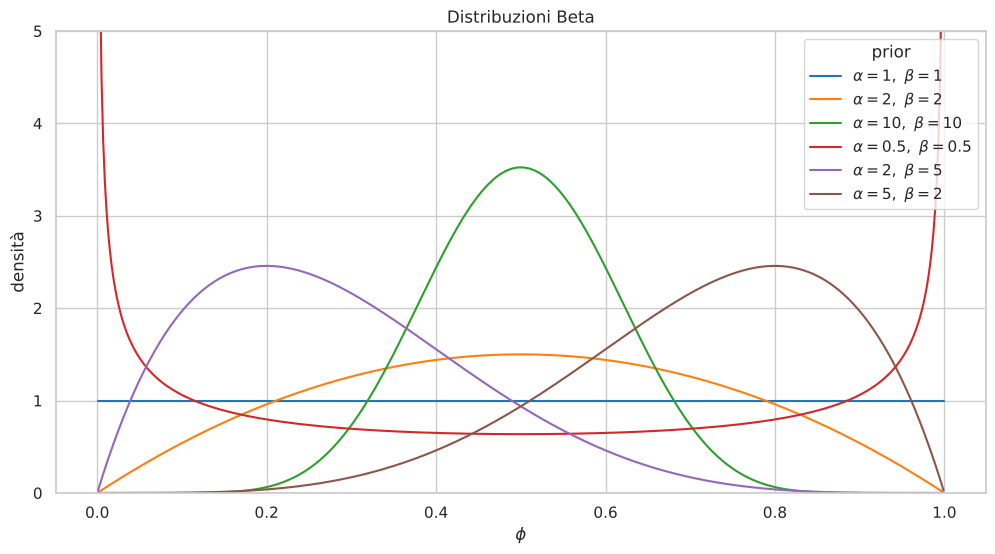

In [6]:
priors = [(1, 1), (2, 2), (10, 10), (0.5, 0.5), (2, 5), (5, 2)]
df = pd.concat([pd.DataFrame({'phi': phis, 'densità': st.beta.pdf(phis, a, b),
                               'prior': r'$\alpha={0},\ \beta={1}$'.format(a, b)}) for a, b in priors])
fig, ax = plt.subplots(figsize=(12,6))
sns.lineplot(data=df, x='phi', y='densità', hue='prior', palette='tab10', ax=ax)
ax.set(ylim=(0, 5), xlabel=r'$\phi$', title='Distribuzioni Beta')
plt.show()

Alcuni casi notevoli:

- $\alpha=\beta=1$ è la distribuzione **uniforme**: nessuna preferenza tra i valori di $\phi$, e nessuno pseudo-conteggio;
- $\alpha=\beta=2$ e $\alpha=\beta=10$ esprimono la convinzione che la moneta sia **circa equa**, debole nel primo caso (un successo e un insuccesso immaginari) e forte nel secondo (nove e nove);
- $\alpha=\beta=0.5$ concentra la probabilità vicino a $0$ e a $1$: si crede che la moneta sia fortemente sbilanciata, senza sapere in quale direzione;
- $(2,5)$ e $(5,2)$ esprimono una preferenza per valori piccoli o grandi di $\phi$.

## Il posterior e la coniugazione

Per la regola di Bayes il **posterior** è proporzionale al prodotto di verosimiglianza e prior:
$$p(\phi\mid\mathbf{x},\alpha,\beta)\propto\phi^{n_1}(1-\phi)^{n_0}\cdot\phi^{\alpha-1}(1-\phi)^{\beta-1}=\phi^{n_1+\alpha-1}(1-\phi)^{n_0+\beta-1},$$
che ha la forma di una Beta con parametri aggiornati:
$$p(\phi\mid\mathbf{x},\alpha,\beta)=\mathrm{Beta}(\phi\mid\alpha+n_1,\ \beta+n_0).$$
Il posterior appartiene alla stessa famiglia del prior: la Beta è il prior **coniugato** della verosimiglianza di Bernoulli, come la gaussiana lo è della verosimiglianza gaussiana nella regressione lineare. L'aggiornamento è una semplice somma: ogni successo incrementa $\alpha$ di $1$, ogni insuccesso incrementa $\beta$ di $1$, e gli pseudo-conteggi del prior si sommano ai conteggi reali.

Da qui discendono sia la stima MAP sia la predizione pienamente bayesiana.

In [7]:
def posterior(x, a, b):
    n1, n0 = counts(x)
    return a + n1, b + n0          # parametri della Beta a posteriori

a0, b0 = 2, 2                      # prior: moneta circa equa, prior debole

## Stima MAP

Quando serve un solo valore, la stima **maximum a posteriori** è la moda del posterior. Annullando la derivata del logaritmo del posterior,
$$\frac{n_1}{\phi}-\frac{n_0}{1-\phi}+\frac{\alpha-1}{\phi}-\frac{\beta-1}{1-\phi}=0\quad\Longrightarrow\quad\phi_{MAP}=\frac{n_1+\alpha-1}{n+\alpha+\beta-2},$$
cioè la moda della Beta con conteggi aumentati. Rispetto alla frequenza osservata, al numeratore si aggiungono gli $\alpha-1$ pseudo-successi e al denominatore i $\alpha+\beta-2$ pseudo-lanci. È l'analogo, per questo modello, della **regolarizzazione**: con pochi dati la stima viene spinta verso la moda del prior, e non può collassare su $0$ o $1$ (per $\alpha,\beta>1$). Con il prior uniforme, $\alpha=\beta=1$, la stima MAP coincide con quella di massima verosimiglianza: un prior piatto non aggiunge nulla.

Con $n_1=1$ successo in $n=1$ lancio e $\alpha=\beta=2$, ad esempio, $\phi_{ML}=1$ ma $\phi_{MAP}=2/3$.

In [8]:
def phi_map(x, a, b):
    n1, n0 = counts(x)
    return (n1 + a - 1)/(n1 + n0 + a + b - 2)

print('un successo in un lancio: phi_ML = {0:.3f}, phi_MAP = {1:.3f}'.format(phi_ml(np.array([1])), phi_map(np.array([1]), a0, b0)))

un successo in un lancio: phi_ML = 1.000, phi_MAP = 0.667


## Approccio pienamente bayesiano

MAP riduce il posterior a un solo punto, la moda. L'approccio pienamente bayesiano conserva l'intera distribuzione, da cui si ottengono:

- una stima puntuale diversa, la **media** a posteriori, che pesa ogni valore di $\phi$ con la sua probabilità a posteriori:
$$\mathbb{E}[\phi\mid\mathbf{x}]=\frac{\alpha+n_1}{\alpha+\beta+n},$$
una media pesata tra la media del prior $\frac{\alpha}{\alpha+\beta}$ e la frequenza osservata $\frac{n_1}{n}$, con pesi proporzionali a $\alpha+\beta$ e a $n$;
- la **distribuzione predittiva** di un nuovo lancio, che media le predizioni di tutti i valori di $\phi$:
$$p(x=1\mid\mathbf{x})=\int_0^1\phi\;p(\phi\mid\mathbf{x})\,d\phi=\mathbb{E}[\phi\mid\mathbf{x}]=\frac{\alpha+n_1}{\alpha+\beta+n}.$$
Per il prior uniforme si ottiene $\frac{n_1+1}{n+2}$, la **regola di successione di Laplace**: dopo $n$ successi su $n$ lanci, la probabilità del prossimo successo è $\frac{n+1}{n+2}$, alta ma mai $1$;
- **intervalli di credibilità**, intervalli di $\phi$ che contengono una frazione fissata, ad esempio il $95\%$, della probabilità a posteriori: a differenza degli intervalli di confidenza frequentisti, si interpretano direttamente come "con probabilità $0.95$, $\phi$ si trova in questo intervallo", dati il prior e le osservazioni.

In [9]:
def phi_mean(x, a, b):
    a1, b1 = posterior(x, a, b)
    return a1/(a1 + b1)

def credible_interval(x, a, b, level=0.95):
    a1, b1 = posterior(x, a, b)
    return st.beta.ppf((1-level)/2, a1, b1), st.beta.ppf((1+level)/2, a1, b1)

## L'evoluzione del posterior

I grafici seguenti mostrano il prior $\mathrm{Beta}(2,2)$ e il posterior dopo $1$, $2$, $5$, $10$, $50$ e $200$ osservazioni, con le tre stime puntuali e l'intervallo di credibilità al $95\%$ (la regione colorata).

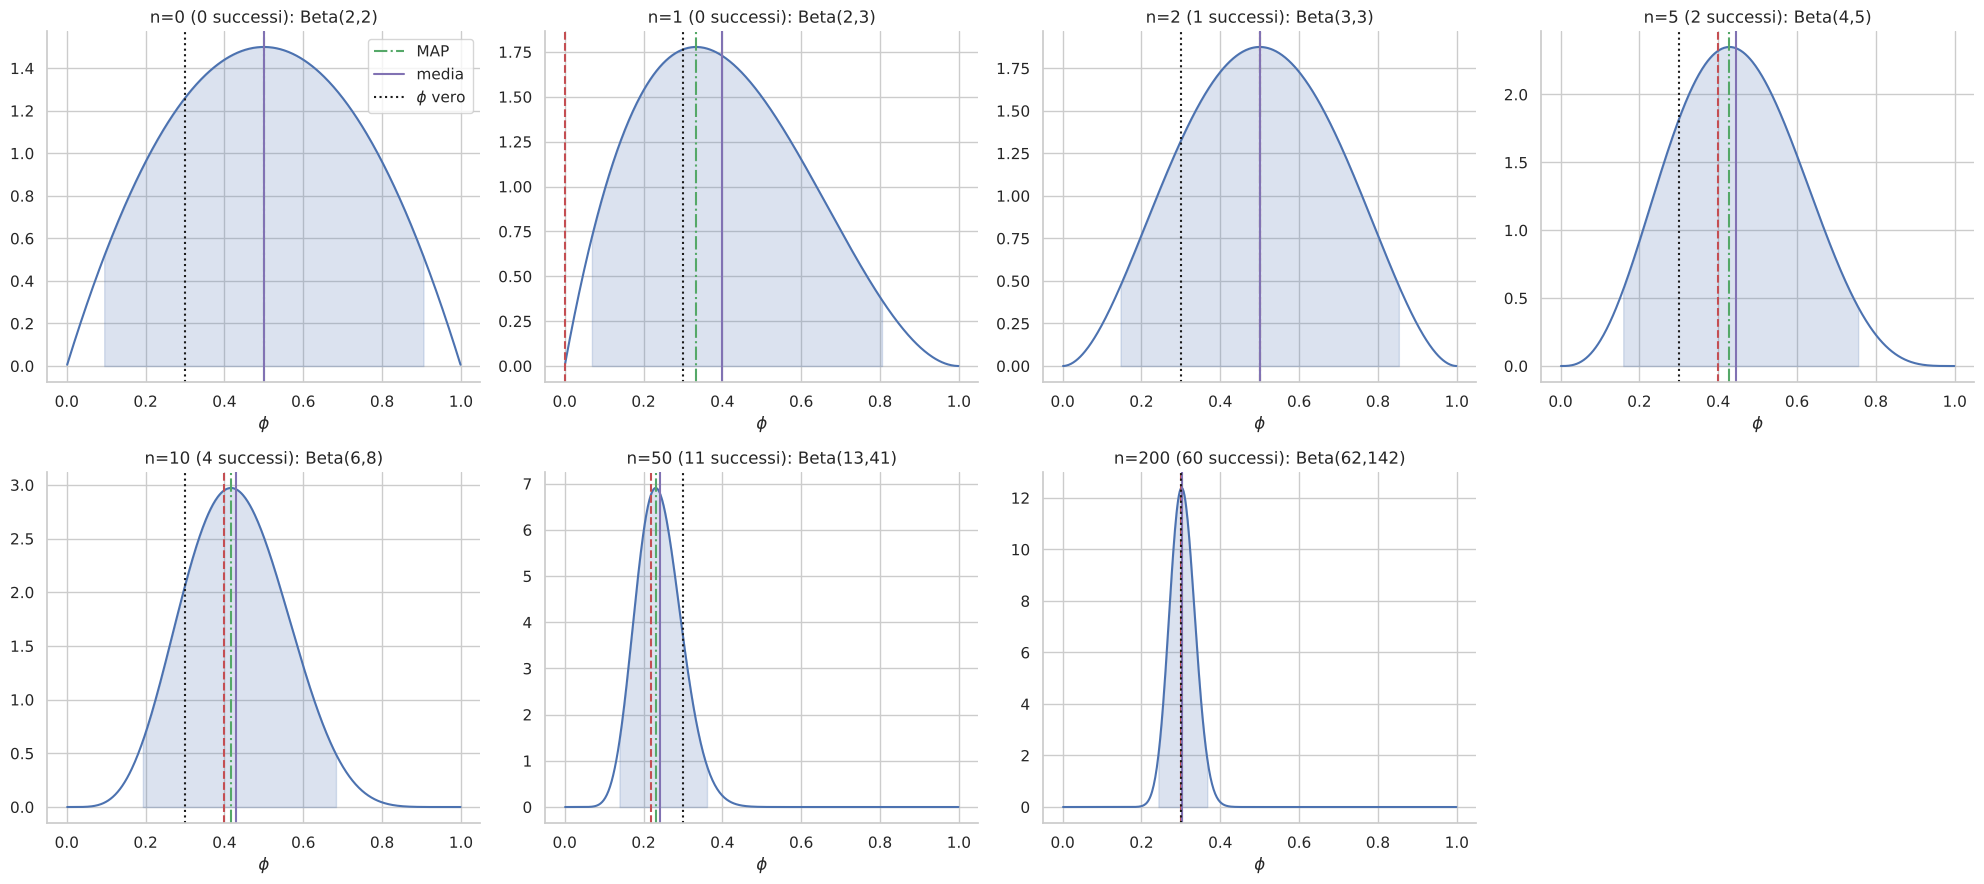

In [10]:
ns = [0, 1, 2, 5, 10, 50, 200]
fig, axs = plt.subplots(2, 4, figsize=(20,9))
axs = axs.ravel()
sns.despine(fig)
for ax, n in zip(axs, ns):
    xs = x[:n]
    a1, b1 = posterior(xs, a0, b0)
    dens = st.beta.pdf(phis, a1, b1)
    sns.lineplot(x=phis, y=dens, color=c_post, ax=ax)
    lo, hi = credible_interval(xs, a0, b0)
    mask = (phis >= lo) & (phis <= hi)
    ax.fill_between(phis[mask], 0, dens[mask], color=c_post, alpha=.2)
    if n > 0:
        ax.axvline(phi_ml(xs), color=c_ml, ls='--', lw=1.5, label='ML')
    ax.axvline(phi_map(xs, a0, b0), color=c_map, ls='-.', lw=1.5, label='MAP')
    ax.axvline(phi_mean(xs, a0, b0), color=c_bayes, ls='-', lw=1.5, label='media')
    ax.axvline(phi_true, color='k', ls=':', lw=1.5, label=r'$\phi$ vero')
    n1, n0 = counts(xs)
    ax.set_title('n={0} ({1} successi): Beta({2},{3})'.format(n, n1, a1, b1))
    ax.set_xlabel(r'$\phi$')
axs[0].legend()
axs[-1].axis('off')
plt.tight_layout()
plt.show()

Come leggere i grafici:

- **prima dei dati** il posterior è il prior, centrato in $0.5$ e molto largo;
- **dopo pochi lanci** il posterior si sposta verso la frequenza osservata, ma resta largo e, in generale, **asimmetrico**: per questo moda (MAP) e media non coincidono, e la media tiene conto della massa di probabilità che sta nella coda. La stima ML, invece, può trovarsi su valori estremi (ad esempio $0$ dopo un solo insuccesso), che il posterior considera poco plausibili;
- **al crescere di $n$** il posterior si concentra attorno al valore vero, diventa quasi simmetrico, e le tre stime si avvicinano fino a coincidere in pratica: i conteggi reali dominano gli pseudo-conteggi del prior, e l'influenza di quest'ultimo svanisce. L'intervallo di credibilità si restringe approssimativamente come $1/\sqrt n$.

## Le tre stime al crescere dei dati

Il grafico seguente riporta le tre stime puntuali in funzione del numero di lanci osservati, insieme all'intervallo di credibilità al $95\%$.

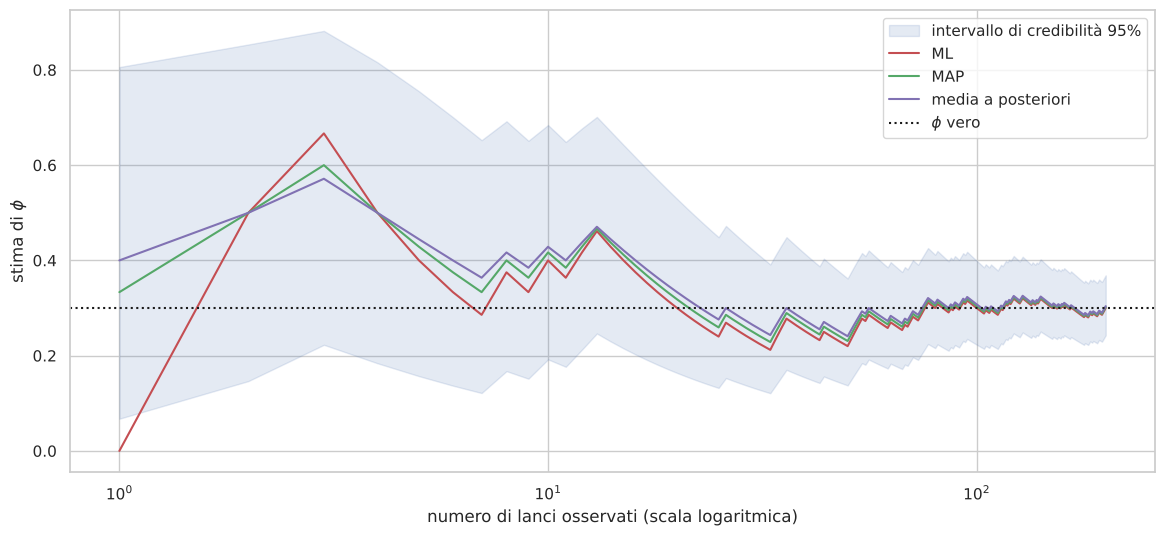

In [11]:
nn = np.arange(1, n_max+1)
ml = np.array([phi_ml(x[:n]) for n in nn])
mp = np.array([phi_map(x[:n], a0, b0) for n in nn])
me = np.array([phi_mean(x[:n], a0, b0) for n in nn])
ci = np.array([credible_interval(x[:n], a0, b0) for n in nn])

df = pd.DataFrame({'n': np.tile(nn, 3),
                   'stima': np.r_[ml, mp, me],
                   'approccio': np.repeat(['ML', 'MAP', 'media a posteriori'], len(nn))})
fig, ax = plt.subplots(figsize=(14,6))
ax.fill_between(nn, ci[:,0], ci[:,1], color=c_post, alpha=.15, label='intervallo di credibilità 95%')
sns.lineplot(data=df, x='n', y='stima', hue='approccio', palette=[c_ml, c_map, c_bayes], lw=1.5, ax=ax)
ax.axhline(phi_true, color='k', ls=':', lw=1.5, label=r'$\phi$ vero')
ax.set(xscale='log', xlabel='numero di lanci osservati (scala logaritmica)', ylabel=r'stima di $\phi$')
ax.legend()
plt.show()

Con pochi dati la stima ML oscilla violentemente, spesso toccando $0$ o $1$; MAP e media a posteriori sono **contratte** verso $0.5$, il centro del prior, e variano molto meno. È il compromesso tra **bias** e **varianza** già incontrato con la regolarizzazione: il prior introduce una distorsione verso $0.5$ (qui sfavorevole, dato che il valore vero è $0.3$), in cambio di una forte riduzione della variabilità delle stime. Al crescere di $n$ le tre curve convergono al valore vero, e la distorsione dovuta al prior scompare.

## Apprendimento sequenziale

Come per la regressione lineare bayesiana, il posterior ottenuto da una parte dei dati può essere usato come prior per la parte successiva, senza dover rivedere i dati già elaborati. Per il modello Beta–Bernoulli l'aggiornamento sequenziale consiste semplicemente nell'incrementare $\alpha$ o $\beta$ a ogni osservazione, e il risultato finale è identico a quello ottenuto elaborando tutti i dati insieme, in qualunque ordine.

In [12]:
a, b = a0, b0
for xi in x:                  # un'osservazione alla volta
    a, b = a + xi, b + (1 - xi)
print('aggiornamento sequenziale:', (a, b))
print('aggiornamento in blocco:  ', posterior(x, a0, b0))

aggiornamento sequenziale: (np.int64(62), np.int64(142))
aggiornamento in blocco:   (62, 142)


## Predizione di più lanci futuri

Per un singolo lancio la distribuzione predittiva è ancora una Bernoulli, con parametro $\mathbb{E}[\phi\mid\mathbf{x}]$: l'incertezza su $\phi$ cambia il valore predetto, ma non è visibile nella forma della distribuzione. Diventa visibile prevedendo il numero di successi $k$ in $m$ lanci futuri. Con un valore fissato $\hat\phi$ (ML o MAP) la predizione è una **binomiale**, $\mathrm{Bin}(k\mid m,\hat\phi)$; integrando sul posterior si ottiene invece la distribuzione **Beta-binomiale**,
$$p(k\mid\mathbf{x})=\int_0^1\mathrm{Bin}(k\mid m,\phi)\,\mathrm{Beta}(\phi\mid\alpha',\beta')\,d\phi=\binom mk\frac{B(\alpha'+k,\ \beta'+m-k)}{B(\alpha',\beta')},$$
con $\alpha'=\alpha+n_1$, $\beta'=\beta+n_0$ e $B$ la funzione Beta. Ha la stessa media della binomiale con $\hat\phi=\mathbb{E}[\phi\mid\mathbf{x}]$, ma una varianza maggiore: alla variabilità dei lanci (incertezza **aleatoria**) si somma quella dovuta all'incertezza su $\phi$ (incertezza **epistemica**), esattamente come nella distribuzione predittiva della regressione lineare bayesiana.

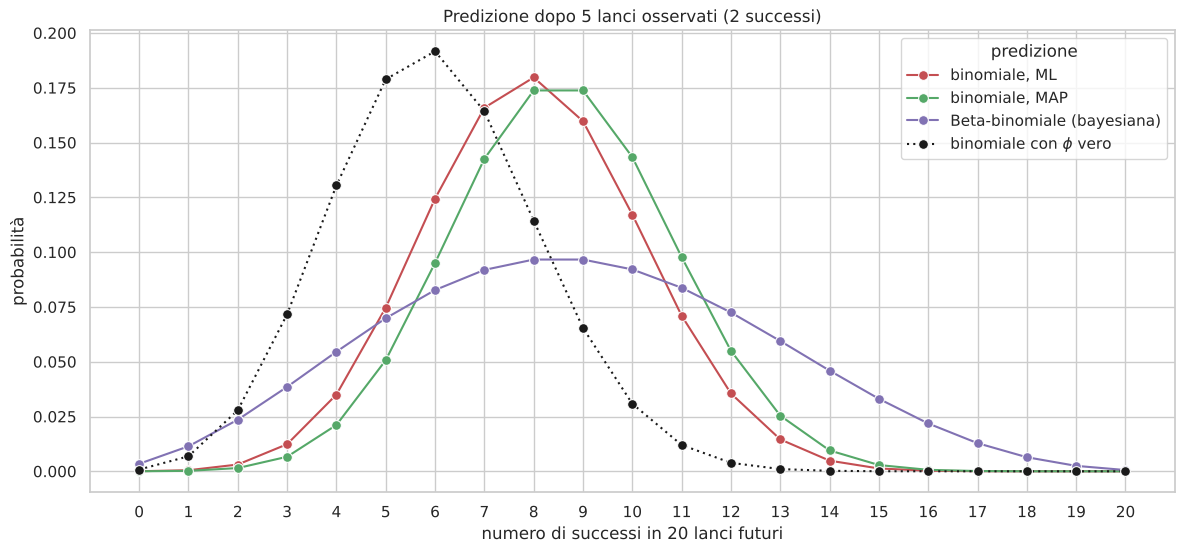

deviazione standard: ML 2.19, MAP 2.21, bayesiana 3.78, vera 2.05


In [13]:
m = 20
n = 5
xs = x[:n]
a1, b1 = posterior(xs, a0, b0)
k = np.arange(m+1)

labels = ['binomiale, ML', 'binomiale, MAP', 'Beta-binomiale (bayesiana)', r'binomiale con $\phi$ vero']
df = pd.DataFrame({'k': np.tile(k, 4),
                   'probabilità': np.r_[st.binom.pmf(k, m, phi_ml(xs)),
                                        st.binom.pmf(k, m, phi_map(xs, a0, b0)),
                                        st.betabinom.pmf(k, m, a1, b1),
                                        st.binom.pmf(k, m, phi_true)],
                   'predizione': np.repeat(labels, len(k))})
fig, ax = plt.subplots(figsize=(14,6))
sns.lineplot(data=df, x='k', y='probabilità', hue='predizione', style='predizione',
             palette=[c_ml, c_map, c_bayes, 'k'], dashes=['', '', '', (1, 2)],
             markers=['o', 'o', 'o', 'o'], markersize=7, lw=1.5, ax=ax)
ax.set(xticks=k, xlabel='numero di successi in {0} lanci futuri'.format(m),
       title='Predizione dopo {0} lanci osservati ({1} successi)'.format(n, counts(xs)[0]))
plt.show()
print('deviazione standard: ML {0:.2f}, MAP {1:.2f}, bayesiana {2:.2f}, vera {3:.2f}'.format(
    st.binom.std(m, phi_ml(xs)), st.binom.std(m, phi_map(xs, a0, b0)), st.betabinom.std(m, a1, b1), st.binom.std(m, phi_true)))

Dopo soli $5$ lanci, le predizioni basate su un unico valore di $\phi$ sono **troppo sicure**: trattano la stima come se fosse esatta. La distribuzione Beta-binomiale è più larga, perché tiene conto del fatto che, con così pochi dati, $\phi$ potrebbe essere sensibilmente diverso dalla stima; assegna quindi probabilità non trascurabile anche a esiti lontani dal valore centrale. Ripetendo la cella con $n$ più grande (ad esempio $200$), le tre distribuzioni diventano quasi identiche: l'incertezza epistemica si annulla e resta solo quella aleatoria.

## Valutazione delle predizioni: la log-loss

Le tre predizioni di un nuovo lancio possono essere confrontate con una **scoring rule** propria, come la **log-loss** $-\log p(x\mid\mathbf{x})$ discussa nelle note: è piccola quando l'esito osservato era stato previsto come probabile, e infinita quando era stato previsto come impossibile.

Per stimarne il valore atteso ripetiamo l'esperimento molte volte: per ogni ripetizione generiamo un training set di $n$ lanci e un test set di $1000$ lanci dalla stessa moneta, e calcoliamo la log-loss media sul test set delle tre predizioni.

In [14]:
def log_loss(p1, x_test):
    # log-loss media della predizione p(x=1) = p1 su un test set
    # il logaritmo e' calcolato solo per l'esito osservato: se questo era stato
    # previsto come impossibile, la log-loss e' infinita
    with np.errstate(divide='ignore'):
        logp = np.where(x_test == 1, np.log(p1), np.log(1-p1))
    return -np.mean(logp)

reps = 2000
print('{0:>4}  {1:>18}  {2:>10}  {3:>12}  {4:>10}'.format('n', 'ML (finita)', 'ML infinita', 'MAP', 'bayesiana'))
for n in [1, 2, 5, 10, 20, 50, 200]:
    ll = {'ML': [], 'MAP': [], 'Bayes': []}
    for r in range(reps):
        xs = st.bernoulli.rvs(phi_true, size=n)
        xt = st.bernoulli.rvs(phi_true, size=1000)
        ll['ML'].append(log_loss(phi_ml(xs), xt))
        ll['MAP'].append(log_loss(phi_map(xs, a0, b0), xt))
        ll['Bayes'].append(log_loss(phi_mean(xs, a0, b0), xt))
    ml = np.array(ll['ML'])
    fin = ml[np.isfinite(ml)]
    ml_str = '{0:.4f}'.format(fin.mean()) if len(fin) > 0 else 'n.d.'
    print('{0:>4}  {1:>18}  {2:>10.1%}  {3:>12.4f}  {4:>10.4f}'.format(
        n, ml_str, np.mean(~np.isfinite(ml)), np.mean(ll['MAP']), np.mean(ll['Bayes'])))
h = -(phi_true*np.log(phi_true) + (1-phi_true)*np.log(1-phi_true))
print('log-loss minima (entropia della moneta vera): {0:.4f}'.format(h))

   n         ML (finita)  ML infinita           MAP   bayesiana


   1                n.d.      100.0%        0.6971      0.6814


   2              0.6931       58.4%        0.6902      0.6727


   5              0.6832       16.9%        0.6694      0.6563


  10              0.6579        2.6%        0.6457      0.6389


  20              0.6408        0.1%        0.6343      0.6312


  50              0.6210        0.0%        0.6200      0.6194


 200              0.6132        0.0%        0.6131      0.6131
log-loss minima (entropia della moneta vera): 0.6109


La tabella riporta, per diversi valori di $n$, la log-loss media delle tre predizioni; per la massima verosimiglianza riporta separatamente la media sui casi in cui è finita e la **frazione di ripetizioni in cui è infinita**, cioè in cui $\phi_{ML}\in\{0,1\}$ e il test set contiene l'esito previsto come impossibile. Il valore minimo raggiungibile è l'**entropia** della moneta vera, ottenuta predicendo con il valore esatto $\phi=0.3$: è la parte irriducibile del rischio, nella decomposizione discussa nelle note.

Con pochi dati la massima verosimiglianza ha log-loss **infinita** in una frazione consistente dei casi, e, anche quando è finita, è peggiore delle altre due: è il prezzo dell'overfitting. MAP e media a posteriori non assegnano mai probabilità zero e hanno log-loss finita e più bassa; tra le due, la media a posteriori, che è la vera predittiva bayesiana, è in genere leggermente migliore con pochissimi dati. Al crescere di $n$ le tre predizioni convergono, e la log-loss si avvicina all'entropia.

## Scelta degli iperparametri: l'evidenza

Gli iperparametri $\alpha$ e $\beta$ sono stati fissati a mano. Come per la regressione lineare, possono essere scelti massimizzando la **verosimiglianza marginale**, o **evidenza**: la probabilità dei dati osservati una volta integrato il parametro secondo il prior. Per il modello Beta–Bernoulli è disponibile in forma chiusa:
$$p(\mathbf{x}\mid\alpha,\beta)=\int_0^1\phi^{n_1}(1-\phi)^{n_0}\,\mathrm{Beta}(\phi\mid\alpha,\beta)\,d\phi=\frac{B(\alpha+n_1,\ \beta+n_0)}{B(\alpha,\beta)}.$$
Conviene parametrizzare il prior con la sua media $\mu=\frac{\alpha}{\alpha+\beta}$ e la sua forza $s=\alpha+\beta$, il numero di pseudo-osservazioni, e calcolare il logaritmo dell'evidenza su una griglia di valori.

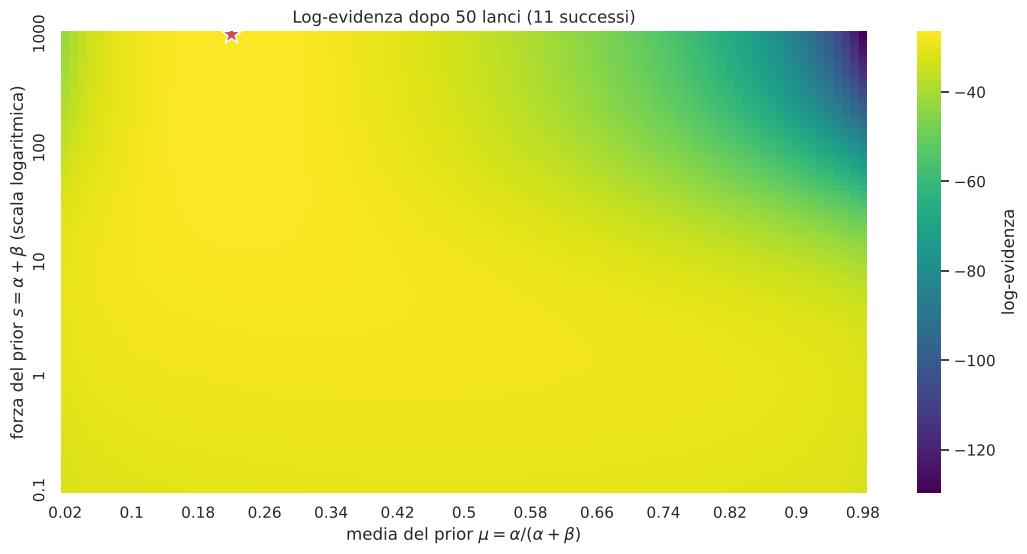

massimo per mu = 0.22, s = 1000.0


In [15]:
def log_evidence(x, a, b):
    n1, n0 = counts(x)
    return betaln(a + n1, b + n0) - betaln(a, b)

n = 50
xs = x[:n]
mus = np.linspace(0.02, 0.98, 97)
ss = np.logspace(-1, 3, 81)
E = np.array([[log_evidence(xs, mu*s, (1-mu)*s) for mu in mus] for s in ss])

i, j = np.unravel_index(np.argmax(E), E.shape)
# heatmap seaborn: righe = forza del prior (dal basso verso l'alto), colonne = media del prior
df = pd.DataFrame(E, index=['{0:g}'.format(v) for v in np.round(ss, 1)], columns=np.round(mus, 2)).iloc[::-1]
fig, ax = plt.subplots(figsize=(13,6))
sns.heatmap(df, cmap='viridis', cbar_kws={'label': 'log-evidenza'}, xticklabels=8, yticklabels=20, ax=ax)
# posizione del massimo (le righe sono invertite)
sns.scatterplot(x=np.ravel(j + .5), y=np.ravel(len(ss) - 1 - i + .5), color='r', marker='*', s=(15)**2, ax=ax)
ax.set(xlabel=r'media del prior $\mu=\alpha/(\alpha+\beta)$', ylabel=r'forza del prior $s=\alpha+\beta$ (scala logaritmica)',
       title='Log-evidenza dopo {0} lanci ({1} successi)'.format(n, counts(xs)[0]))
plt.show()
print('massimo per mu = {0:.2f}, s = {1:.1f}'.format(mus[j], ss[i]))

L'evidenza è massima per una media del prior vicina alla frequenza osservata, e cresce con la forza del prior: con una sola moneta, i dati sono spiegati meglio da un prior molto concentrato esattamente sul valore che li ha prodotti, e al limite l'evidenza preferisce un prior degenere, un punto. È un limite noto della massimizzazione dell'evidenza quando gli iperparametri descrivono una sola sorgente di dati: il prior viene "appreso" dagli stessi dati che dovrebbe regolarizzare.

L'**empirical Bayes** diventa davvero utile quando si osservano **molte monete** (molti gruppi) che si assumono estratte dallo stesso prior, ad esempio i tassi di successo di molti giocatori, o di molti prodotti: l'evidenza calcolata su tutti i gruppi stima allora la distribuzione dei tassi nella popolazione, e il posterior di ciascun gruppo viene contratto verso la media comune, in misura maggiore per i gruppi con pochi dati. È l'idea dei **modelli gerarchici**, che si limita qui a menzionare.

## Considerazioni finali

Il modello Beta–Bernoulli contiene, in forma elementare, tutti gli elementi dell'apprendimento probabilistico visti per la regressione lineare:

- la **massima verosimiglianza** stima il parametro con la frequenza osservata; è semplice e, con molti dati, corretta, ma con pochi dati va in overfitting e può assegnare probabilità zero a esiti possibili;
- il **prior** coniugato Beta si comporta come un insieme di pseudo-osservazioni, e la stima **MAP** corrisponde a una regolarizzazione che contrae la stima verso il prior;
- l'approccio **pienamente bayesiano** conserva l'intero posterior, ne usa la media per le predizioni, fornisce intervalli di credibilità e distribuzioni predittive che includono l'incertezza sul parametro;
- con abbastanza dati i tre approcci coincidono: le differenze contano quando i dati sono pochi rispetto alla complessità del modello, che qui significa pochissimi lanci, e per la regressione molti parametri.